Stock Price Prediction Model Comparison:
LinearRegression: MAE=5.57, RMSE=6.32, R2=-0.45
RidgeRegression: MAE=2.51, RMSE=2.53, R2=0.77
RandomForest: MAE=2.78, RMSE=2.80, R2=0.72


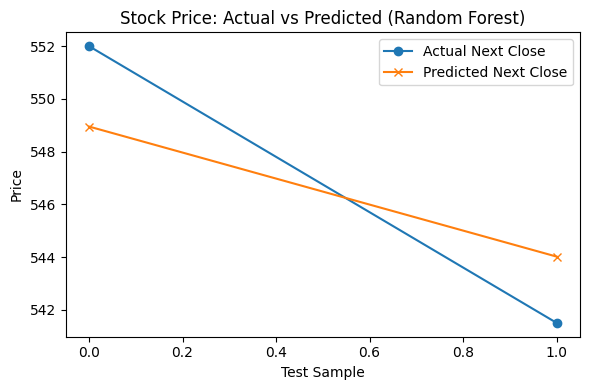

/tmp/ipython-input-671167514.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_names, y=importances, palette='mako')


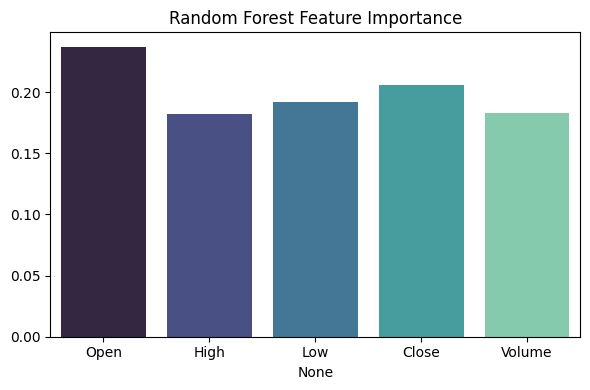


Predicted Next Close for new sample: 551.55


In [1]:
# Stock Price Prediction Using Regression

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Synthetic Sample Data (can be replaced with real data)
sample_data = pd.DataFrame({
    'Open': [540.0, 542.5, 541.0, 540.5, 543.0, 544.0, 545.5, 548.0, 547.5, 550.0],
    'High': [545.0, 543.5, 542.0, 543.0, 546.0, 545.5, 548.0, 551.0, 549.0, 553.0],
    'Low': [539.0, 540.0, 540.5, 539.5, 542.0, 543.5, 545.0, 547.0, 546.5, 548.5],
    'Close': [543.5, 542.0, 541.5, 541.0, 545.0, 545.0, 546.5, 550.5, 548.5, 552.0],
    'Volume': [2500000, 2200000, 2350000, 2100000, 2400000, 2600000, 2700000, 2850000, 2550000, 2650000],
    'Next_Close': [542.0, 541.5, 541.0, 545.0, 545.0, 546.5, 550.5, 548.5, 552.0, 553.0]
})

# 2. Features and target
X = sample_data[['Open', 'High', 'Low', 'Close', 'Volume']]
y = sample_data['Next_Close']

# 3. Preprocessing: Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# 5. Model definition and training
models = {
    "LinearRegression": LinearRegression(),
    "RidgeRegression": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42)
}
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    }

# 6. Print metrics table
print("Stock Price Prediction Model Comparison:")
for name, metrics in results.items():
    print(f"{name}: MAE={metrics['MAE']:.2f}, RMSE={metrics['RMSE']:.2f}, R2={metrics['R2']:.2f}")

# 7. Visualization: Actual vs Predicted for Random Forest
best_model = models['RandomForest']
y_pred_best = best_model.predict(X_test)
plt.figure(figsize=(6,4))
plt.plot(y_test.values, label='Actual Next Close', marker='o')
plt.plot(y_pred_best, label='Predicted Next Close', marker='x')
plt.title('Stock Price: Actual vs Predicted (Random Forest)')
plt.xlabel('Test Sample')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

# 8. Feature Importance
importances = best_model.feature_importances_
feat_names = X.columns
plt.figure(figsize=(6,4))
sns.barplot(x=feat_names, y=importances, palette='mako')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

# 9. Demo prediction for a new sample data
new_sample = pd.DataFrame([{
    'Open': 553.0,
    'High': 555.0,
    'Low': 550.0,
    'Close': 552.0,
    'Volume': 2700000
}])
scaled_sample = scaler.transform(new_sample)
predicted_price = best_model.predict(scaled_sample)[0]
print(f"\nPredicted Next Close for new sample: {predicted_price:.2f}")

